Autorzy: Brojek

# Programming assignment 1

In this exercise you are going to learn one of leading NLP Libraries:

https://www.nltk.org/




# 1 Sourcing
Download 5-10 books with requests library  (https://docs.python-requests.org/en/latest/).

You can find English books in plain text format on: https://www.gutenberg.org/browse/scores/top). Polish books are available on: https://wolnelektury.pl/


Create **corpora**  as list where each element of list contains text from single book




In [17]:
links = [
    "https://wolnelektury.pl/media/book/txt/quo-vadis.txt",             # Quo vadis
    "https://wolnelektury.pl/media/book/txt/pan-tadeusz.txt",           # Pan Tadeusz
    "https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt",     # Lalka - Tom I
    "https://wolnelektury.pl/media/book/txt/lalka-tom-drugi.txt",        # Lalka - Tom II
    "https://wolnelektury.pl/media/book/txt/krzyzacy-tom-pierwszy.txt", # Krzyżacy - Tom I
    "https://wolnelektury.pl/media/book/txt/krzyzacy-tom-drugi.txt",    # Krzyżacy - Tom II
    "https://wolnelektury.pl/media/book/txt/wesele.txt",                # Wesele
    "https://wolnelektury.pl/media/book/txt/kordian.txt",               # Kordian
    "https://wolnelektury.pl/media/book/txt/balladyna.txt"              # Balladyna
]
corpus=[]

import requests
from bs4 import BeautifulSoup
requests.encoding = "utf-8"
for link in links:
    print(link)
    response=requests.get(link)
    decoded_text = response.content.decode('utf-8')
    print(response.status_code)
    response.encoding='utf-8'
    corpus.append(BeautifulSoup(decoded_text,'html.parser').get_text())
    #print(corpus[-1][:200])
# add up to 10 more and save it in list.
# download it with https://docs.python-requests.org/en/latest/

#expected outocme
#corpus  = [' Thisis the content of the first book',
#           'thisis the conent of the second book',
#           'thisis the conent of the third book' ]


https://wolnelektury.pl/media/book/txt/quo-vadis.txt
200
https://wolnelektury.pl/media/book/txt/pan-tadeusz.txt
200
https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt
200
https://wolnelektury.pl/media/book/txt/lalka-tom-drugi.txt
200
https://wolnelektury.pl/media/book/txt/krzyzacy-tom-pierwszy.txt
200
https://wolnelektury.pl/media/book/txt/krzyzacy-tom-drugi.txt
200
https://wolnelektury.pl/media/book/txt/wesele.txt
200
https://wolnelektury.pl/media/book/txt/kordian.txt
200
https://wolnelektury.pl/media/book/txt/balladyna.txt
200


# 2  Preprocessing

Preprocess documents using nltk library:

* remove stopwords
* remove tokens containing non-alphanumeric characters
* apply lowercase

https://www.nltk.org/book_1ed/ch03.html





In [22]:
# nltk library
!pip install nltk
!python -m spacy download pl_core_news_sm
import  nltk

from nltk.corpus import stopwords
import spacy

nlp = spacy.load("pl_core_news_sm")

stop_words=set(stopwords.words('english')).union(nlp.Defaults.stop_words)
corpus_transformed=[]

from nltk.tokenize import word_tokenize

for book in corpus:
    book= word_tokenize(book,language="polish")
    corpus_transformed.append(" ".join([word.lower() for word in book if word.lower() not in stop_words and word.isalnum()]))

  Using cached https://github.com/explosion/spacy-models/releases/download/pl_core_news_sm-3.8.0/pl_core_news_sm-3.8.0-py3-none-any.whl (20.2 MB)
✔ Download and installation successful
You can now load the package via spacy.load('pl_core_news_sm')


/# 3 Word Frequency and Zipf Law

For each document create frequency plots. You can use any of this:
* CountVectorizer from sklearn library
* plain counter


Check whether Zipf's law holds for  selected documents.

Example output:

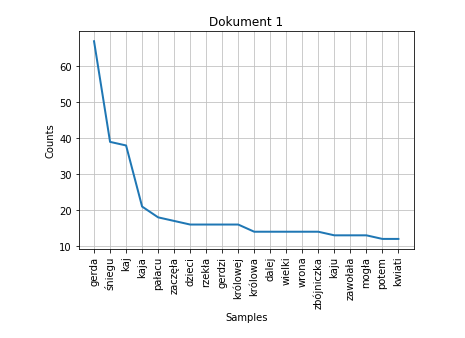

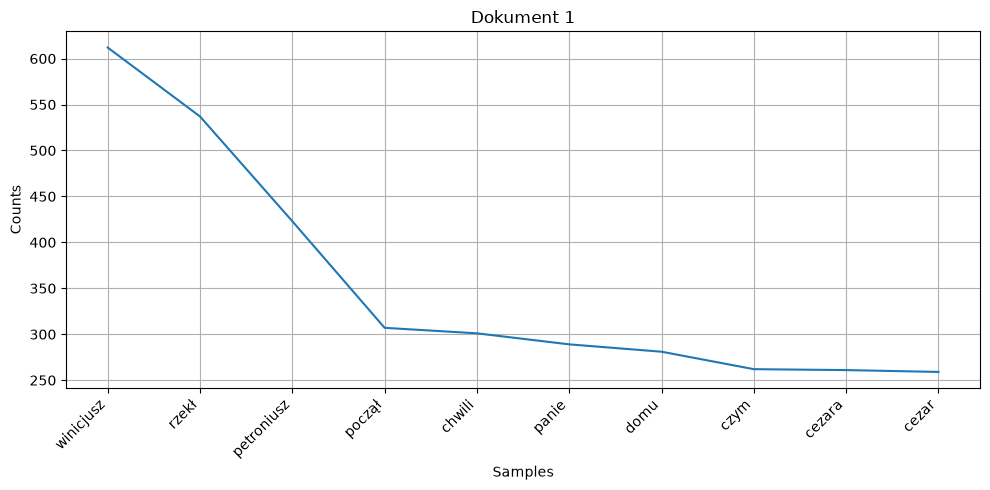

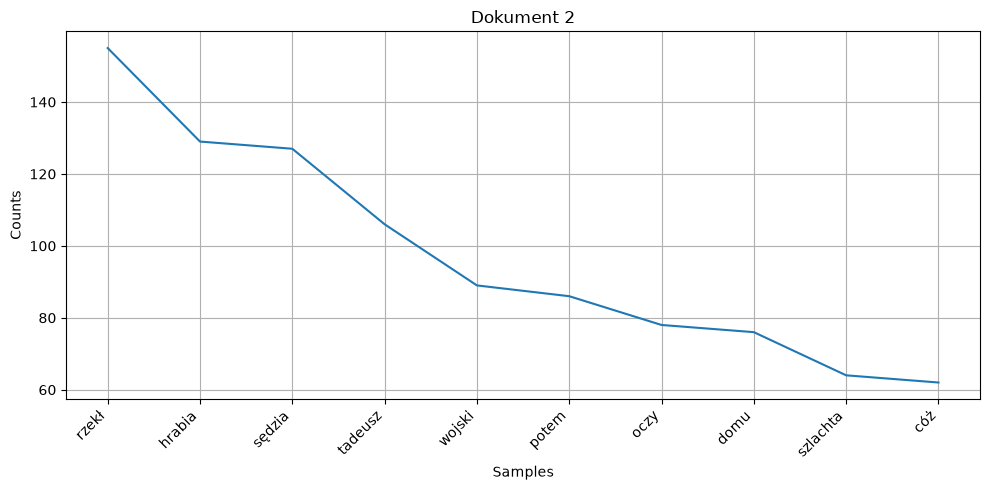

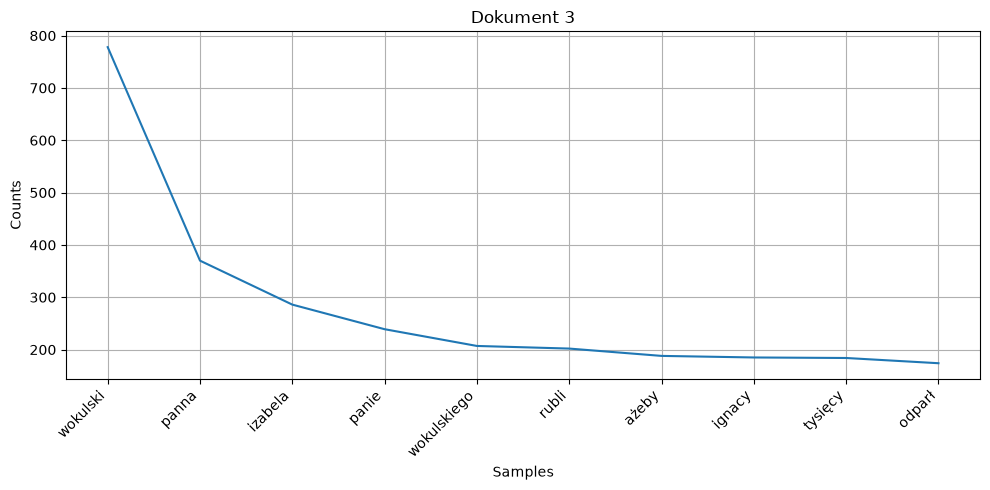

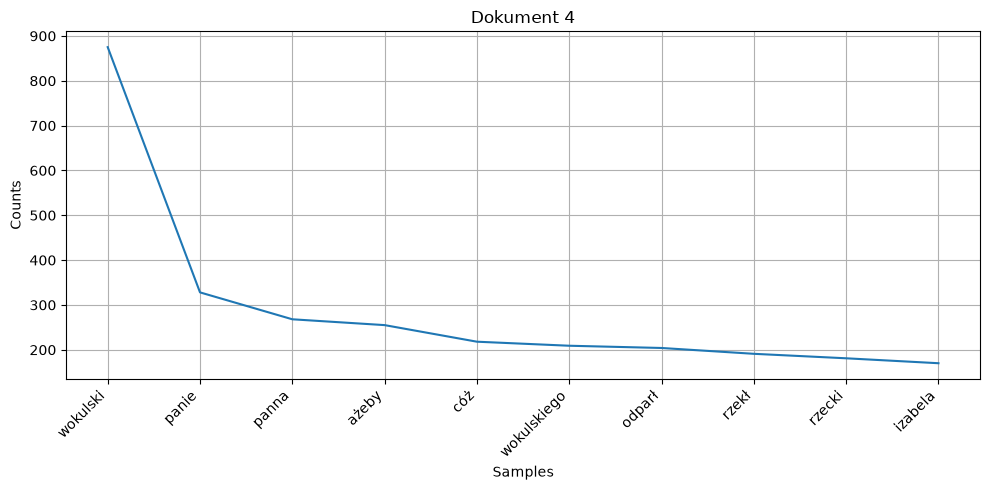

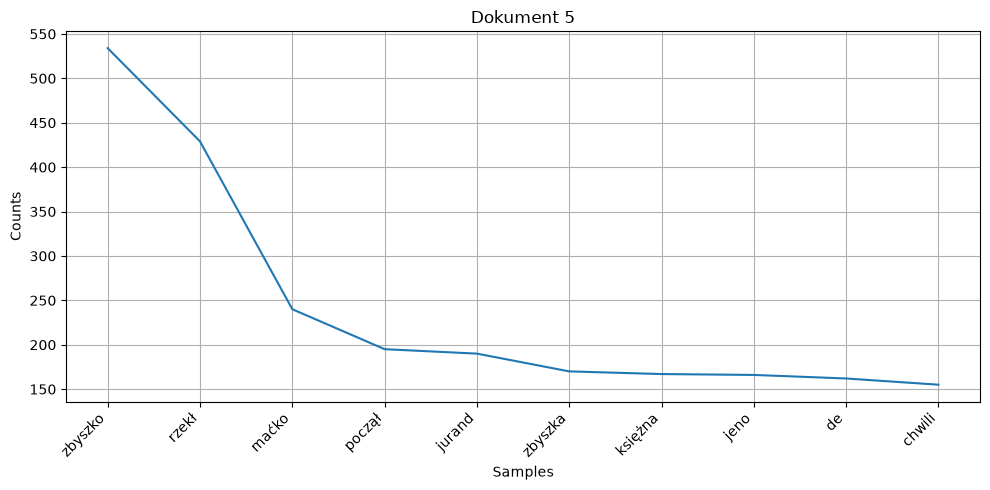

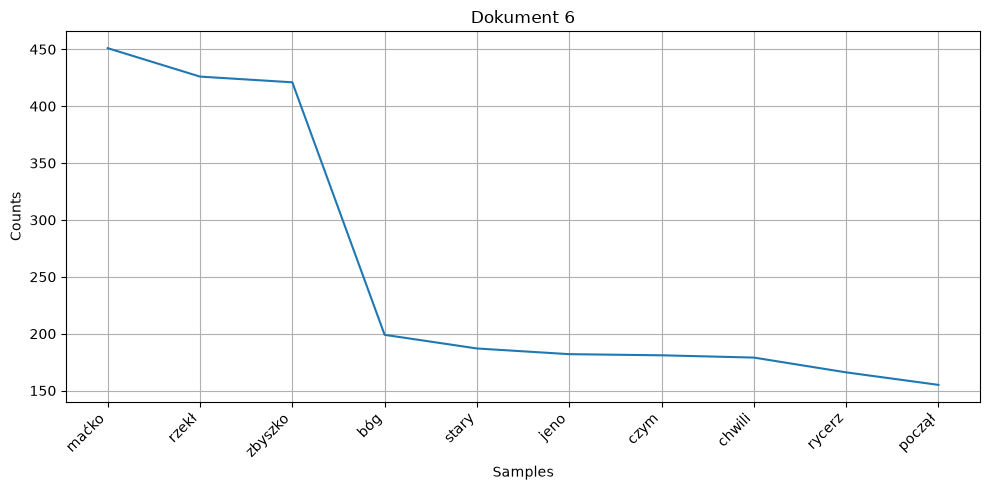

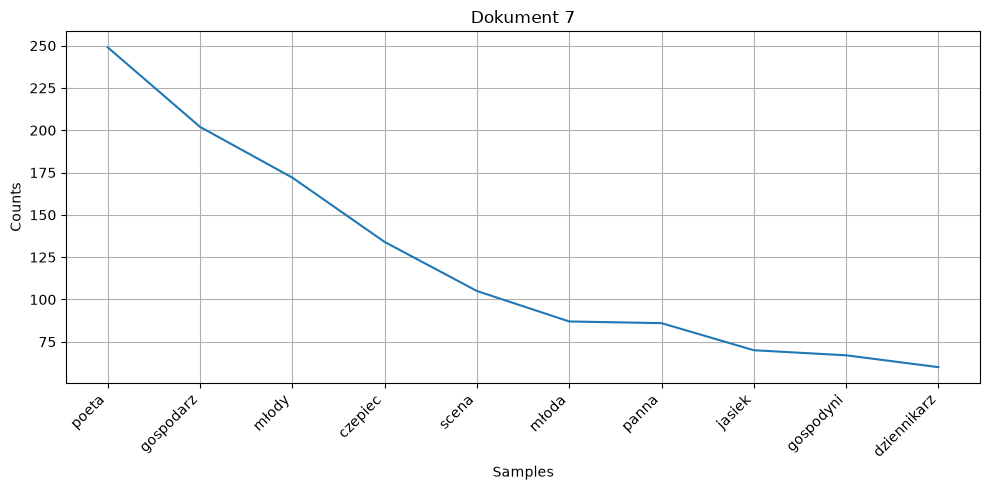

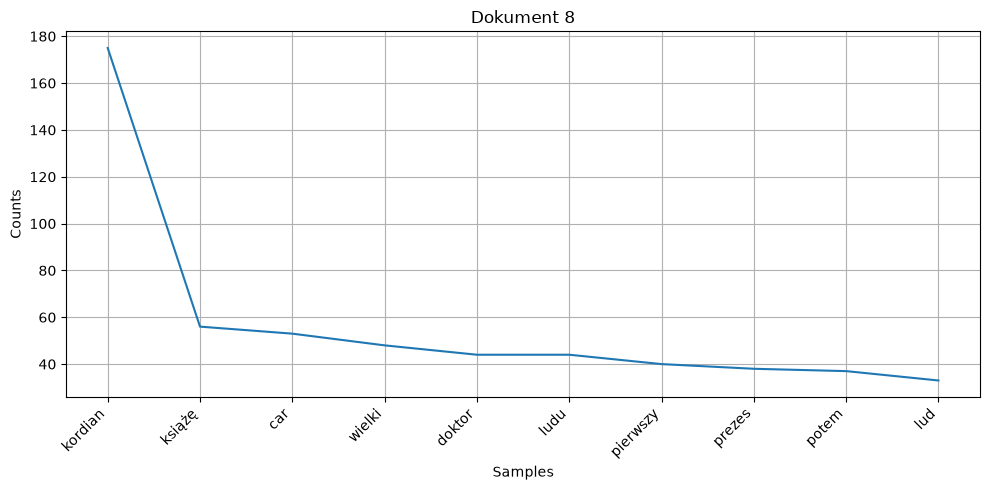

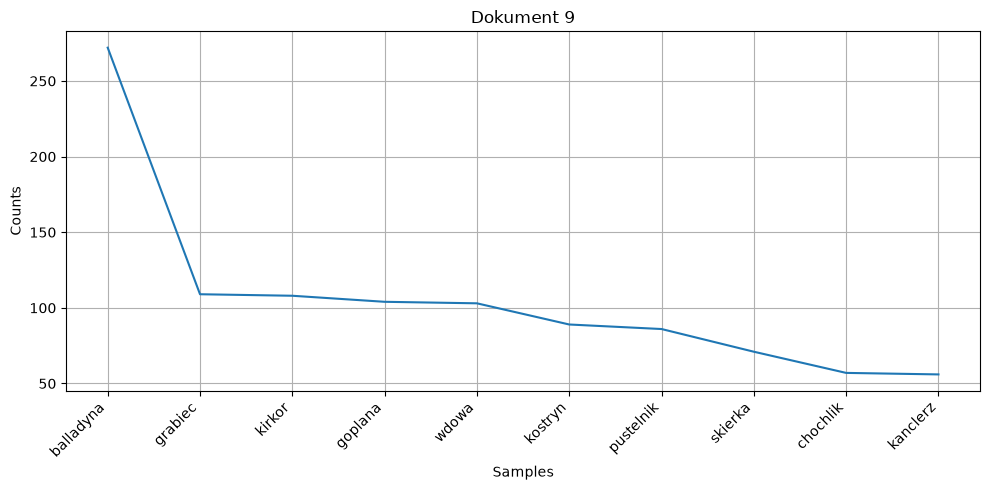

In [29]:
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer


vectorizer = CountVectorizer()
X=vectorizer.fit_transform(corpus_transformed)

import pandas as pd
import matplotlib.pyplot as plt
df_counts = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out(),index=[f"Dokument {i+1}" for i in range(len(corpus_transformed))])

for title, row in df_counts.iterrows():
    top=row.nlargest(10).sort_values(ascending=False)

    plt.figure(figsize=(10, 5))
    top.plot(kind='line')
    plt.xticks(range(len(top)), top.index, rotation=45, ha='right')
    plt.xlabel('Samples')
    plt.ylabel('Counts')
    plt.grid(True)
    plt.title(title)
    plt.tight_layout()
    plt.show()



# 4 TF-IDF

Create TF-IDF matrix for corpus using TfidfVectorizer

https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html




In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer=TfidfVectorizer()
X_tfidf=tfidf_vectorizer.fit_transform(corpus_transformed)

feature_names=tfidf_vectorizer.get_feature_names_out()
df_tfidf = pd.DataFrame(
    X_tfidf.toarray(),
    columns=feature_names,
    index=[f"Dokument {i+1}" for i in range(len(corpus_transformed))]
)

for title, row in df_tfidf.iterrows():

    print(row.sort_values(ascending=False).head(10))


winicjusz     0.470084
petroniusz    0.324911
cezar         0.198941
winicjusza    0.195100
ligia         0.182042
ligii         0.178202
rzekł         0.174725
cezara        0.169326
nero          0.142101
ligię         0.126738
Name: Dokument 1, dtype: float64
tadeusz       0.268178
wojski        0.225169
sędzia        0.208482
hrabia        0.188962
rzekł         0.166114
gerwazy       0.151799
telimena      0.141679
tadeusza      0.136619
klucznik      0.129029
podkomorzy    0.100433
Name: Dokument 2, dtype: float64
wokulski       0.675883
izabela        0.248461
wokulskiego    0.179830
rubli          0.175486
ignacy         0.160718
panna          0.145844
sklepu         0.095174
panie          0.094207
odparł         0.093049
izabeli        0.092087
Name: Dokument 3, dtype: float64
wokulski       0.699021
wokulskiego    0.166966
rzecki         0.144598
izabela        0.135810
wąsowska       0.122961
panie          0.118891
baron          0.115304
ochocki        0.108648
stawskiej

# 5 Document similarity

Using cosine similarity find similarity between documents for each pair of documents in the corpus. You can use: #https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html

Print similarity  matrix for the corpus.

Which two documents are the most similar ones? Which are different ? Write your answer in text cell below.

In [43]:
from sklearn.metrics.pairwise import cosine_similarity

similarity=cosine_similarity(X_tfidf)
df_similarity = pd.DataFrame(
    similarity,
    columns=[f"Dokument {i+1}" for i in range(len(corpus_transformed))],
    index=[f"Dokument {i+1}" for i in range(len(corpus_transformed))]
)

pd.set_option('display.max_columns', None)
pd.set_option('expand_frame_repr', False)
print(df_similarity.round(3))

import numpy as np
np.fill_diagonal(similarity, np.nan)

# Największe podobieństwo
max_idx = np.unravel_index(np.nanargmax(similarity), similarity.shape)
print(f"Najbardziej podobne: Książka_{max_idx[0]+1} i Książka_{max_idx[1]+1} (Wynik: {similarity[max_idx]:.4f})")

# Najmniejsze podobieństwo
min_idx = np.unravel_index(np.nanargmin(similarity), similarity.shape)
print(f"Najmniej podobne: Książka_{min_idx[0]+1} i Książka_{min_idx[1]+1} (Wynik: {similarity[min_idx]:.4f})")

            Dokument 1  Dokument 2  Dokument 3  Dokument 4  Dokument 5  Dokument 6  Dokument 7  Dokument 8  Dokument 9
Dokument 1       1.000       0.208       0.158       0.162       0.258       0.267       0.054       0.102       0.057
Dokument 2       0.208       1.000       0.186       0.181       0.222       0.238       0.094       0.159       0.088
Dokument 3       0.158       0.186       1.000       0.869       0.152       0.159       0.071       0.090       0.050
Dokument 4       0.162       0.181       0.869       1.000       0.155       0.161       0.068       0.088       0.053
Dokument 5       0.258       0.222       0.152       0.155       1.000       0.858       0.066       0.099       0.056
Dokument 6       0.267       0.238       0.159       0.161       0.858       1.000       0.070       0.108       0.061
Dokument 7       0.054       0.094       0.071       0.068       0.066       0.070       1.000       0.071       0.043
Dokument 8       0.102       0.159       0.090  

Your comment on this:

Najbardziej podobne okazały się książki 3 i 4, co po zostanowieniu nie powinno dziwić, ponieważ wzięto dwa tomy tej samej opowieści, więc wiadomo że bedą one dzielić podobne sobie słowa.

Nawet analizując wykresy występowania słów widać podobieństwa takie jak "wokulski","panna" itp.

Analogiczne zachowanie występuje dla 5 i 6, gdzie są to również dwa tomy tej samej powieści.

Najmniej podobne okazały się "Wesele" i "Balladyna".


# 7  PCA
Using PCA (Principal Component Analysis)  represent each document as a point in 2-dimensional space.

https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html


Visulize documents on  dot-chart. Remember to add observation labels (doc titles) to points on chart.

How does output correlate to similarity matrix  ?

Example output:

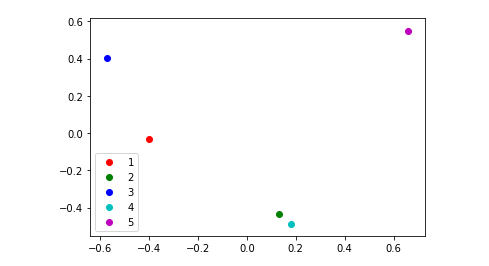

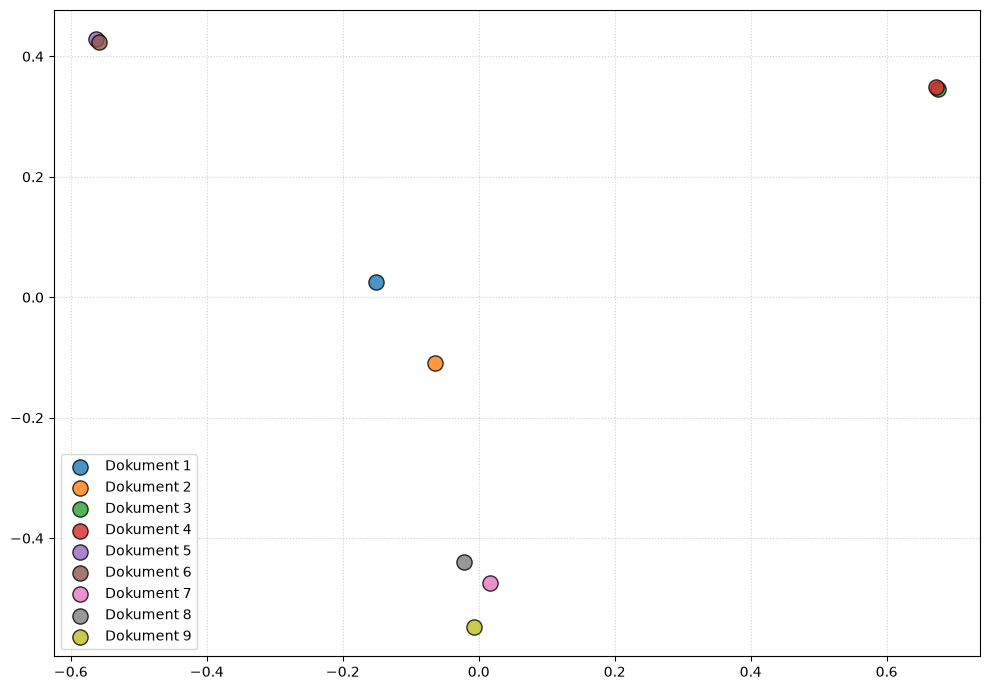

In [50]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
coords_2d=pca.fit_transform(X_tfidf.toarray())

df_pca=pd.DataFrame(
    coords_2d,
    columns=['PC1','PC2'],
    index=[f"Dokument {i+1}" for i in range(len(corpus_transformed))]
)
plt.figure(figsize=(10, 7))

for title, row in df_pca.iterrows():
    plt.scatter(
        row['PC1'],
        row['PC2'],
        s=120,
        alpha=0.8,
        edgecolors='black',
        label=title
    )

plt.legend([f"Dokument {i+1}" for i in range(len(corpus_transformed))])
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Wynik jest zbliżony do podobieńśtwa cosinusowego pod względem dokumentów z największą zgodnością, najbardziej zbliżone sa 3 z 4 i 5 z 6 ale widać, że 3 i 4 bardziej sie pokrywają co zgadza sie z cosine_similarity.

Ciekawe jest znajdowanie sie dokumentów teoretycznie najmniej podobnych blisko siebie, aczkolwiek jest to spowodowane horendalną redukcją wymiarowości, gdzie oryginalny korpus ma wiele słów czyli wymiarów i redukujemy go do jedynie dwóch, siłą rzeczy tracimy dużo informacji pozwalających rozróżnić książki.
